# Diamond price regression: Review 1

Problem → dataset/EDA → cleaning and features → methods → results → team conclusion. Predict diamond prices from physical measurements and categorical quality attributes.

## Shared preparation and evaluation
All ten algorithms use the same 80:20 split, stratified by price deciles (seed 42), and identical base preprocessing. Drop the identifier before duplicate removal. Convert invalid physical dimensions to missing, create `volume=x*y*z`, then learn median imputation, 1.5-IQR clipping, scaling and categorical one-hot encoding inside each training fold. Never fit transforms on the test set. The geometric volume feature follows the original project; the team must justify its predictive use.

GridSearchCV uses five shuffled training folds and R². Every algorithm-specific grid is shown in the output. SVR additionally standardizes the target inside TransformedTargetRegressor using training-fold statistics, then returns predictions in original price units. Polynomial Regression applies PolynomialFeatures to numeric predictors only and compares degrees 2 and 3. Category encodings are identical across algorithms. All predictions are evaluated in original price units, using R², RMSE and MAE. Regression's split is stratified by target bins, not by nonexistent class labels.

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'r1/review1_pipeline.py').is_file())
sys.path.insert(0, str(root / 'r1'))
sys.path.insert(0, str(root / 'r2'))
import review1_pipeline as review

data = review.diamonds_data()

Shape: (2100, 11) | Exact duplicates: 0
Nonpositive dimensions converted to missing: {'x': 0, 'y': 0, 'z': 0}
Cleaned rows: 2099 | Train: 1679 | Test: 420


,id: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1389,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
1,50053,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
2,41646,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
3,42378,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
4,17245,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


,dtype,missing
id: 0,int64,0
carat,float64,0
cut,str,0
color,str,0
clarity,str,0
depth,float64,0
table,float64,0
price,int64,0
x,float64,0
y,float64,0


,price
count,2100.000000
mean,3971.387143
std,4124.225067
min,360.000000
25%,926.750000
50%,2324.500000
75%,5357.250000
max,18803.000000


,IQR_outliers
carat,64
depth,114
table,26
x,1
y,1
z,1
volume,49


### Team observation: dataset audit and preprocessing justification

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## EDA: numeric and categorical feature distributions

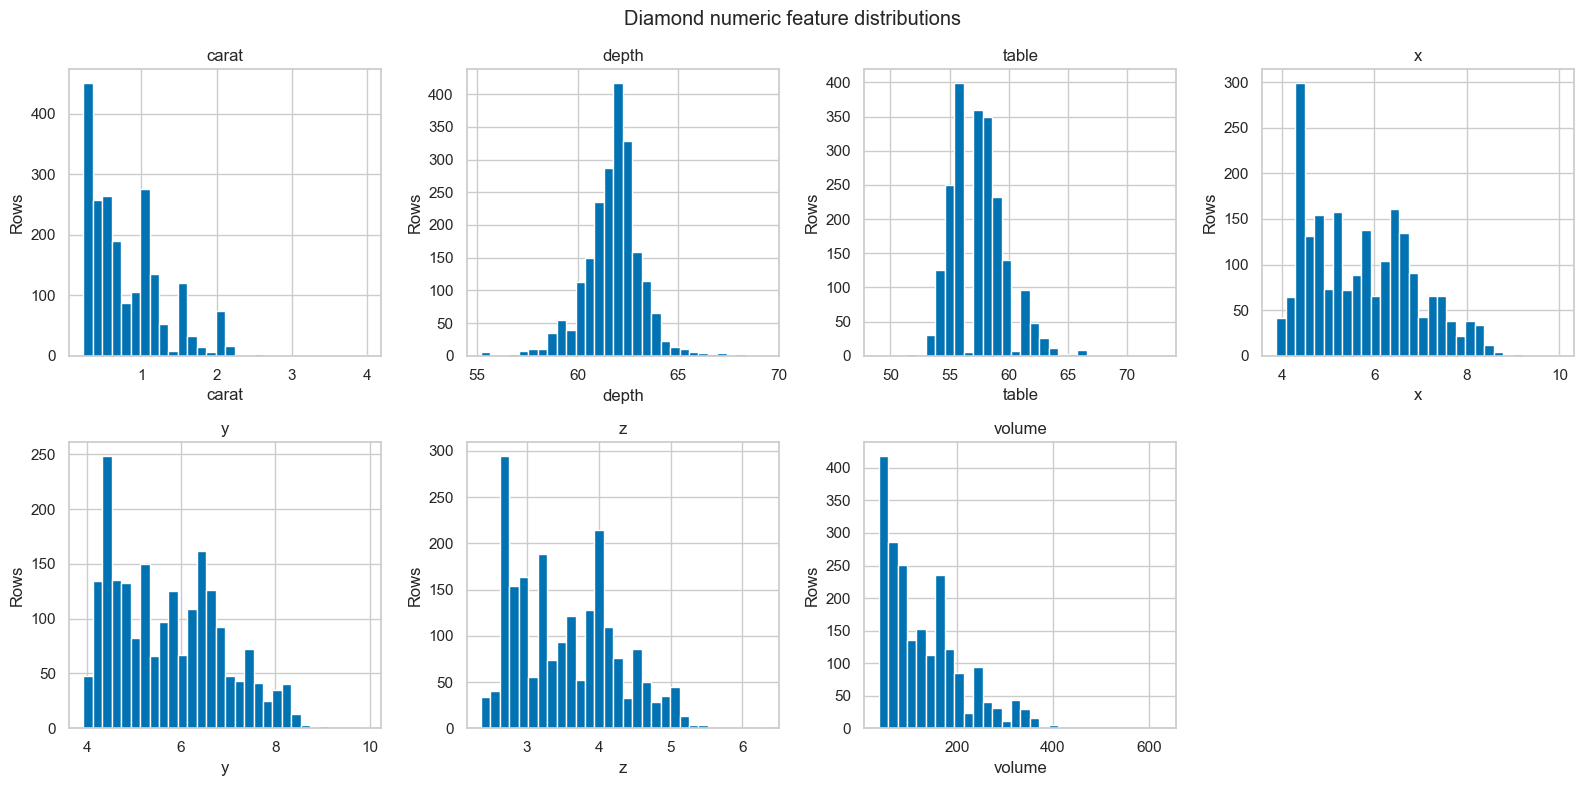

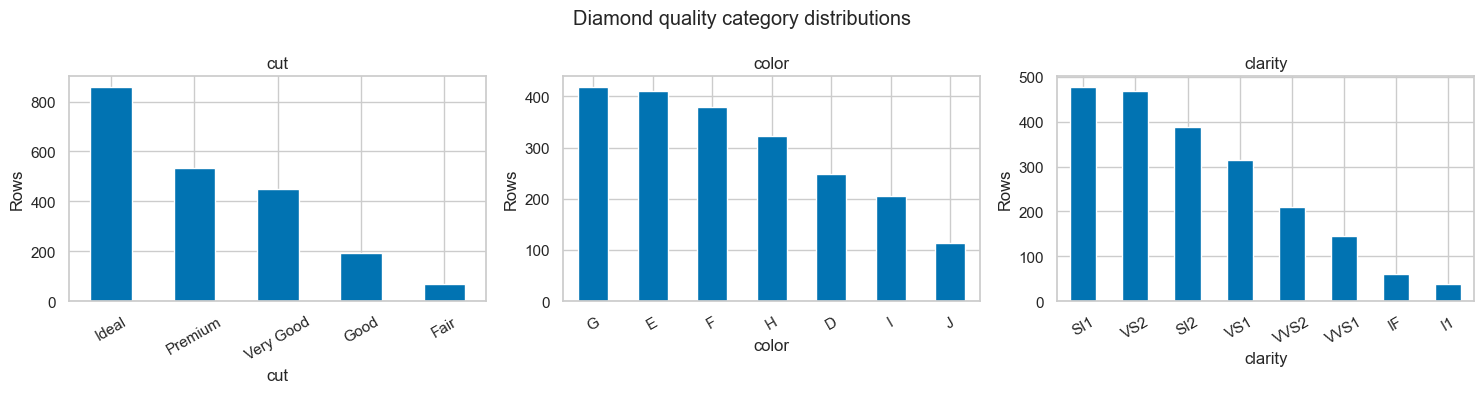

In [2]:
review.diamond_eda(data, 'distributions')

### Team observation: numeric and categorical feature distributions

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## EDA: correlation heatmap

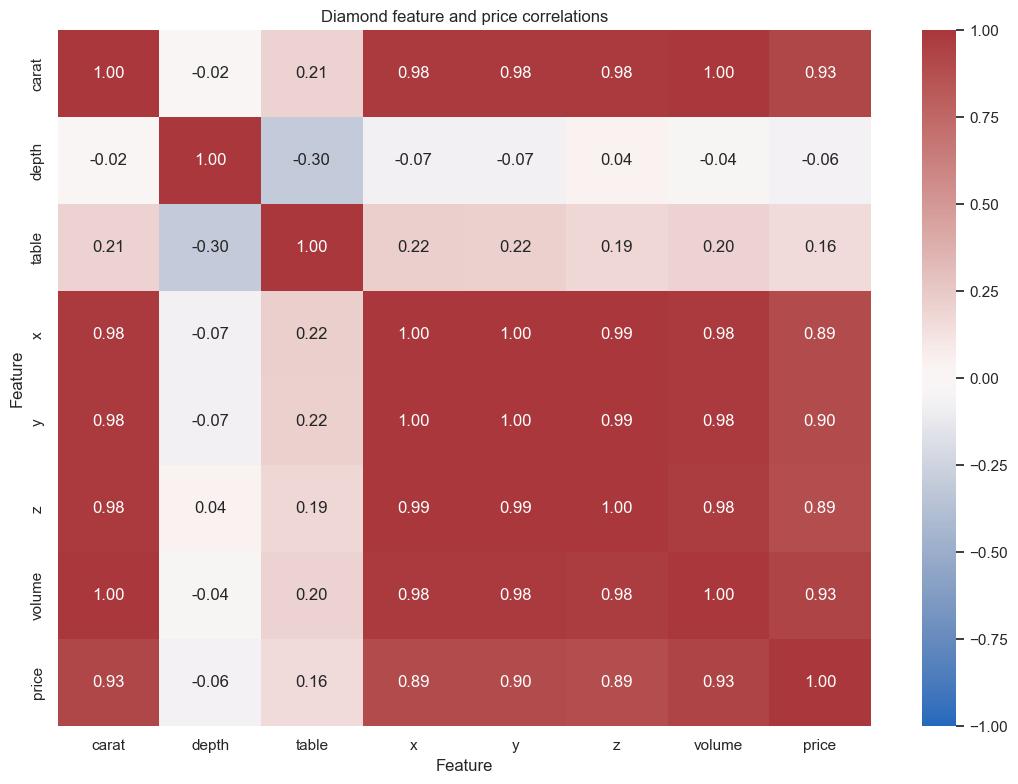

In [3]:
review.diamond_eda(data, 'correlation')

### Team observation: correlation heatmap

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## EDA: price distribution

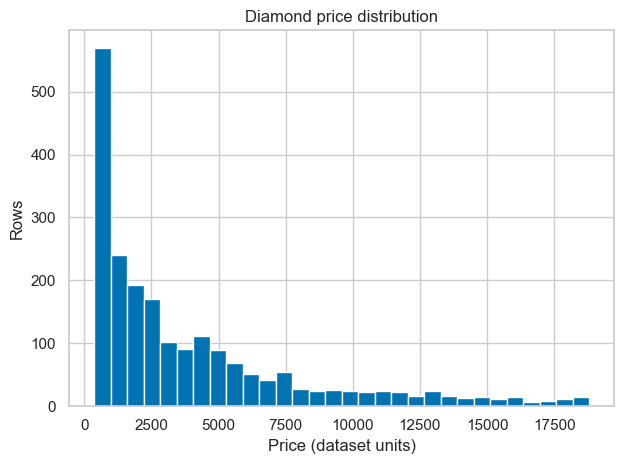

In [4]:
review.diamond_eda(data, 'target')

### Team observation: price distribution

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## EDA: two feature-target scatter plots

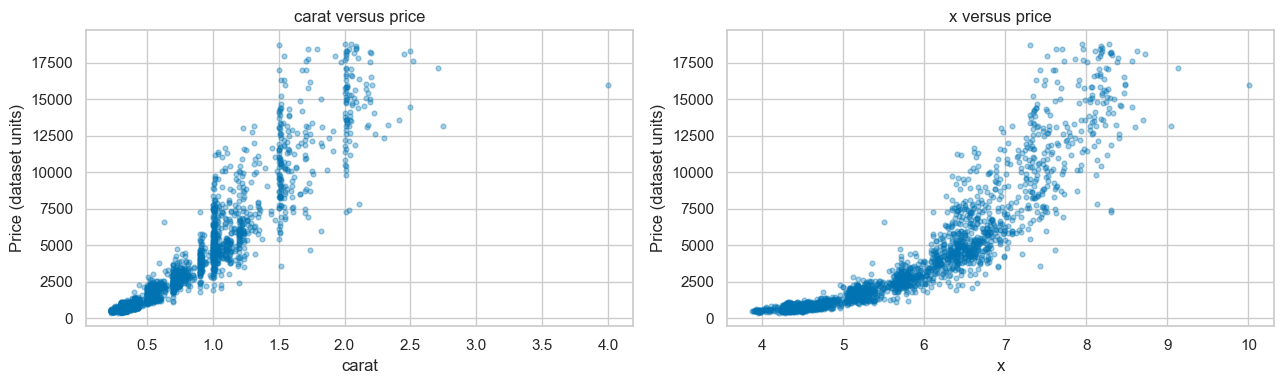

In [5]:
review.diamond_eda(data, 'scatter')

### Team observation: two feature-target scatter plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Linear Regression
Display coefficients for the standardized numeric and encoded category inputs. The team should interpret conditional signs and multicollinearity.

Linear Regression | Best parameters: {} | Training CV R2: 0.9342740577441383


,Metric,Baseline,Tuned,Change
0,R2,0.935195,0.935195,0.0
1,RMSE,1054.271075,1054.271075,0.0
2,MAE,697.477719,697.477719,0.0


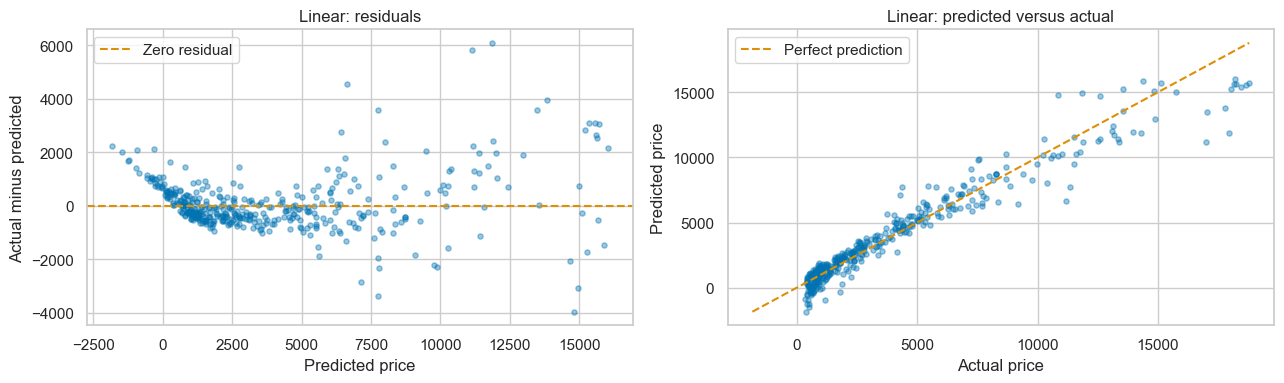

,Feature,Coefficient
0,carat,118.067447
1,depth,196.760740
2,table,25.292210
3,x,-2143.882011
4,y,1341.904180
5,z,-1633.561908
6,volume,6621.106774
7,cut_Good,516.779903
8,cut_Ideal,694.174269
9,cut_Premium,725.867011


In [6]:
result = review.run_regressor('Linear Regression', data)

### Team observation: Linear Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Ridge Regression
Tune alpha to compare L2 regularization strengths.

Ridge Regression | Best parameters: {'model__alpha': 0.1} | Training CV R2: 0.9344125604576708


,Metric,Baseline,Tuned,Change
0,R2,0.934458,0.935157,0.000699
1,RMSE,1060.249958,1054.579628,-5.670330
2,MAE,687.469180,696.185465,8.716285


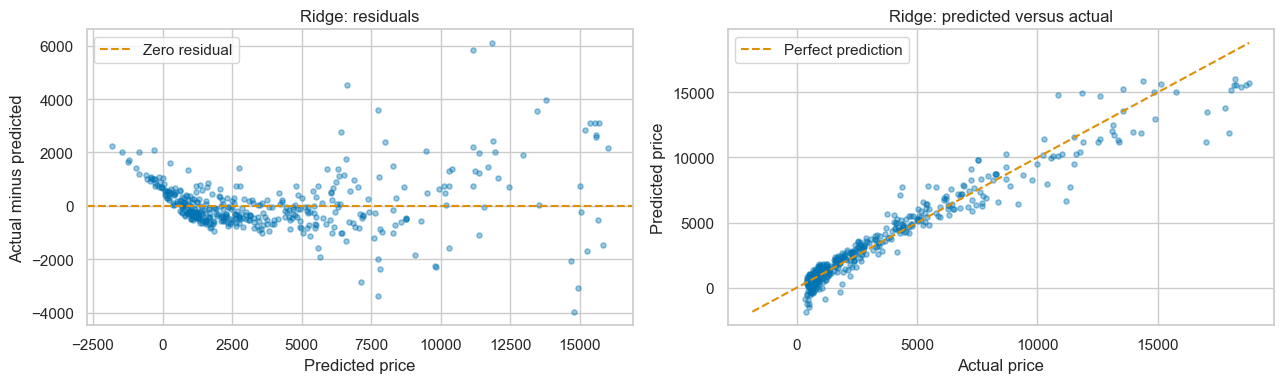

,Feature,Coefficient
0,carat,453.293504
1,depth,189.630739
2,table,20.035564
3,x,-2126.686717
4,y,1333.189914
5,z,-1631.028604
6,volume,6273.138790
7,cut_Good,527.125713
8,cut_Ideal,704.326437
9,cut_Premium,733.440074


In [7]:
result = review.run_regressor('Ridge Regression', data)

### Team observation: Ridge Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Lasso Regression
Tune alpha and report the actual number of zero/nonzero coefficients to support the team sparsity discussion.

Lasso Regression | Best parameters: {'model__alpha': 0.1} | Training CV R2: 0.9343191348344131
Lasso zero coefficients: 0 / 24


,Metric,Baseline,Tuned,Change
0,R2,0.935373,0.935244,-0.000128
1,RMSE,1052.827803,1053.873517,1.045714
2,MAE,689.082935,696.546805,7.463870


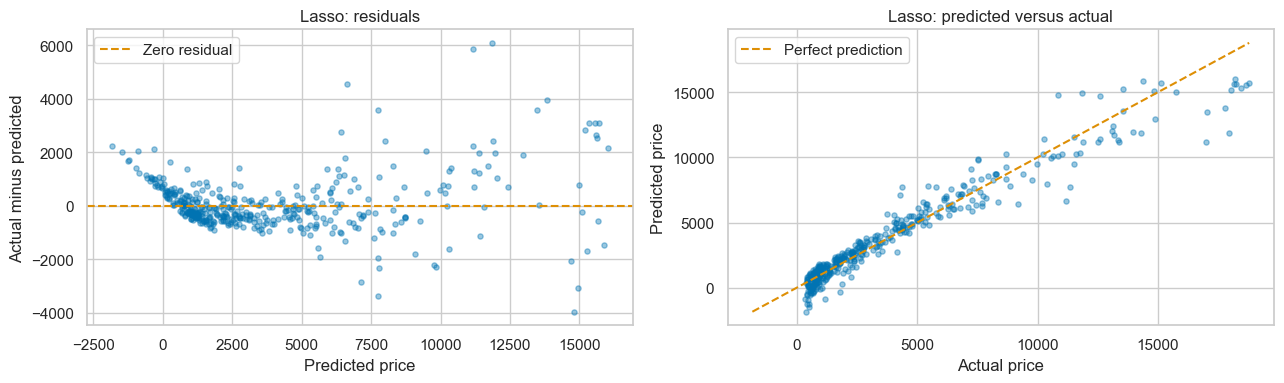

,Feature,Coefficient
0,carat,86.279182
1,depth,185.604473
2,table,24.358169
3,x,-2100.719770
4,y,1214.991799
5,z,-1546.724993
6,volume,6648.462203
7,cut_Good,515.397742
8,cut_Ideal,688.087463
9,cut_Premium,717.250781


In [8]:
result = review.run_regressor('Lasso Regression', data)

### Team observation: Lasso Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## ElasticNet Regression
Tune both alpha and l1_ratio to compare combined L1/L2 regularization.

ElasticNet Regression | Best parameters: {'model__alpha': 0.001, 'model__l1_ratio': 0.9} | Training CV R2: 0.9344405622884709


,Metric,Baseline,Tuned,Change
0,R2,0.926123,0.935126,0.009003
1,RMSE,1125.652992,1054.834351,-70.818641
2,MAE,709.002605,695.331291,-13.671313


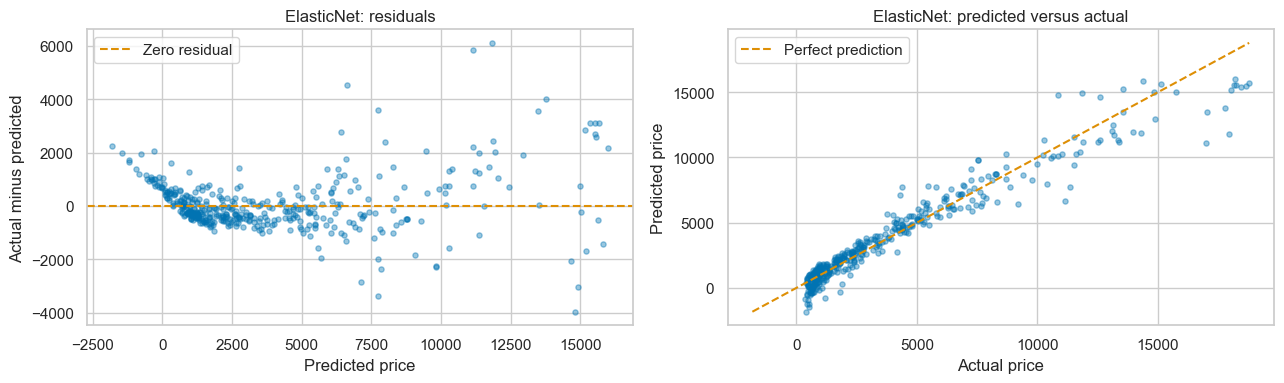

,Feature,Coefficient
0,carat,639.055271
1,depth,184.718572
2,table,16.993048
3,x,-2111.065313
4,y,1316.105992
5,z,-1622.683855
6,volume,6079.266134
7,cut_Good,533.738347
8,cut_Ideal,710.428275
9,cut_Premium,737.742565


In [9]:
result = review.run_regressor('ElasticNet Regression', data)

### Team observation: ElasticNet Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Polynomial Regression
Compare polynomial degrees 2 and 3 using training CV R²; avoid redundant one-hot polynomial squares by expanding only numeric features.

Polynomial Regression | Best parameters: {'preprocessor__num__polynomial__degree': 2} | Training CV R2: 0.9141481119517613


,Metric,Baseline,Tuned,Change
0,R2,0.934149,0.934149,0.0
1,RMSE,1062.744297,1062.744297,0.0
2,MAE,692.804134,692.804134,0.0


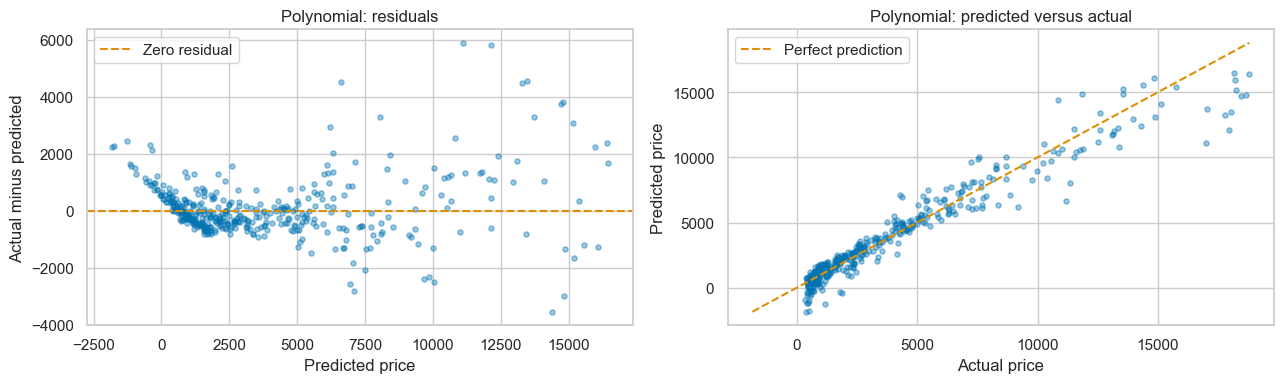

,Feature,Coefficient
0,carat,976.176479
1,depth,385.707563
2,table,31.318922
3,x,702.631127
4,y,3466.588236
5,z,-3920.986444
6,volume,2869.546806
7,carat^2,-19235.608079
8,carat depth,-1253.848867
9,carat table,4520.518047


In [10]:
result = review.run_regressor('Polynomial Regression', data)

### Team observation: Polynomial Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Decision Tree Regression
Tune max_depth and minimum leaf size, then show fitted tree feature importance.

Decision Tree Regression | Best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 3} | Training CV R2: 0.8958981094159698


,Metric,Baseline,Tuned,Change
0,R2,0.881399,0.898813,0.017414
1,RMSE,1426.240297,1317.379766,-108.860530
2,MAE,694.636905,656.527196,-38.109709


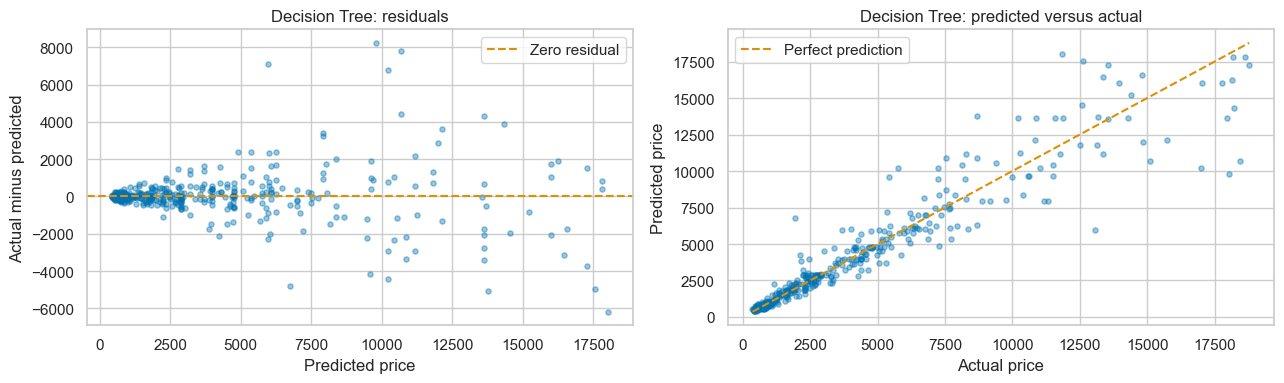

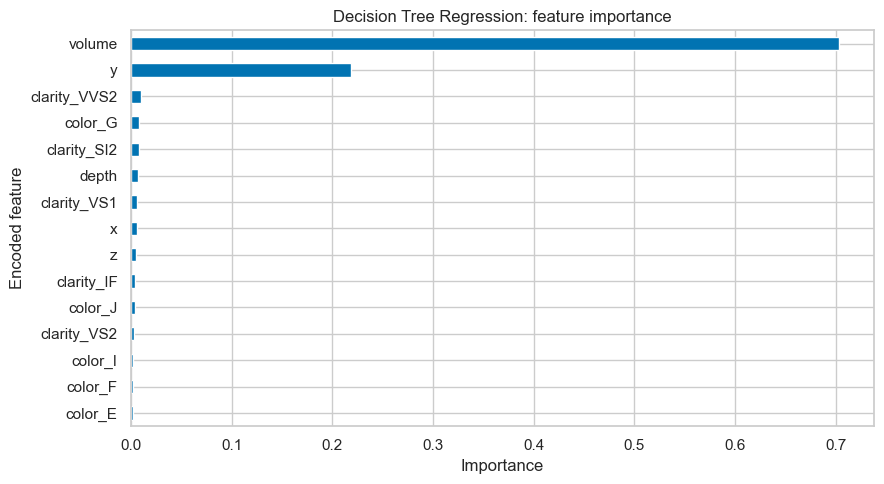

In [11]:
result = review.run_regressor('Decision Tree Regression', data)

### Team observation: Decision Tree Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Random Forest Regression
Tune n_estimators, max_depth and minimum leaf size; display fitted feature importance.

Random Forest Regression | Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200} | Training CV R2: 0.9357402922194474


,Metric,Baseline,Tuned,Change
0,R2,0.923553,0.924145,0.000592
1,RMSE,1145.065102,1140.622824,-4.442277
2,MAE,549.812802,549.306027,-0.506775


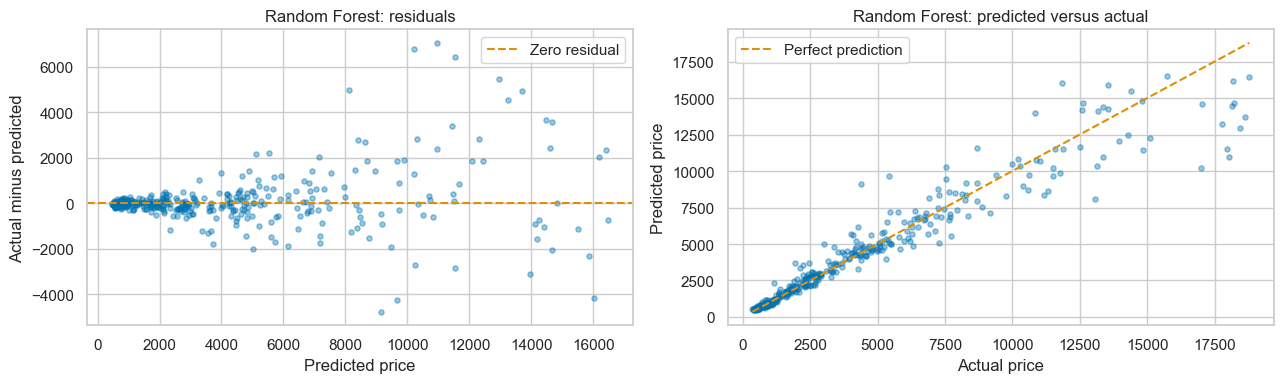

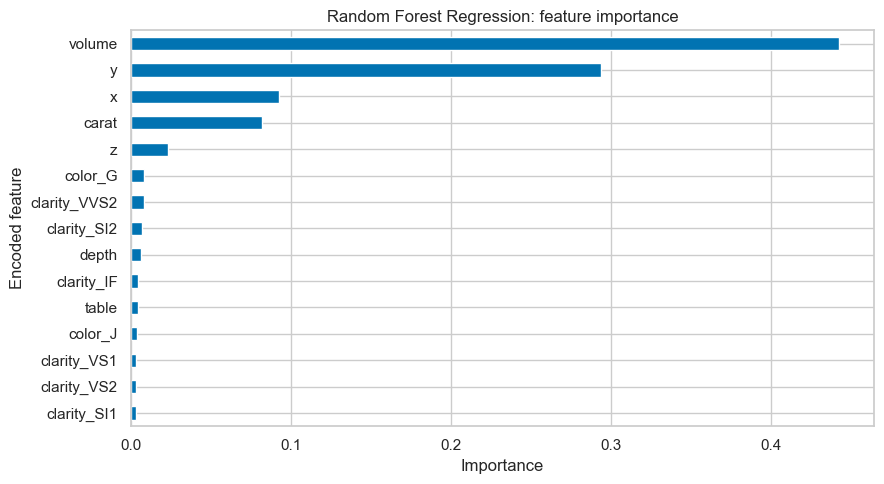

In [12]:
result = review.run_regressor('Random Forest Regression', data)

### Team observation: Random Forest Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Gradient Boosting Regression
Tune learning_rate, n_estimators and max_depth; display fitted feature importance.

Gradient Boosting Regression | Best parameters: {'model__learning_rate': 0.15, 'model__max_depth': 3, 'model__n_estimators': 150} | Training CV R2: 0.9431709463019698


,Metric,Baseline,Tuned,Change
0,R2,0.931410,0.930859,-0.000551
1,RMSE,1084.625846,1088.975294,4.349448
2,MAE,528.398098,511.795296,-16.602802


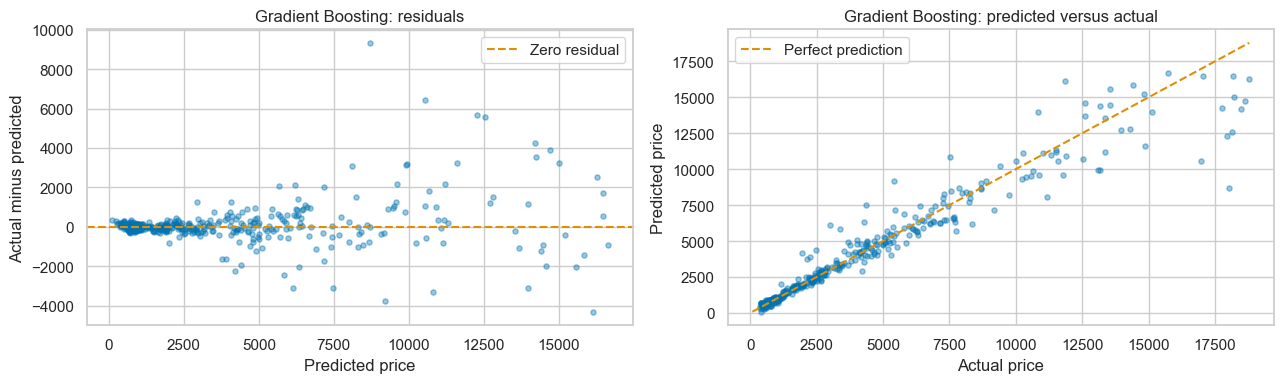

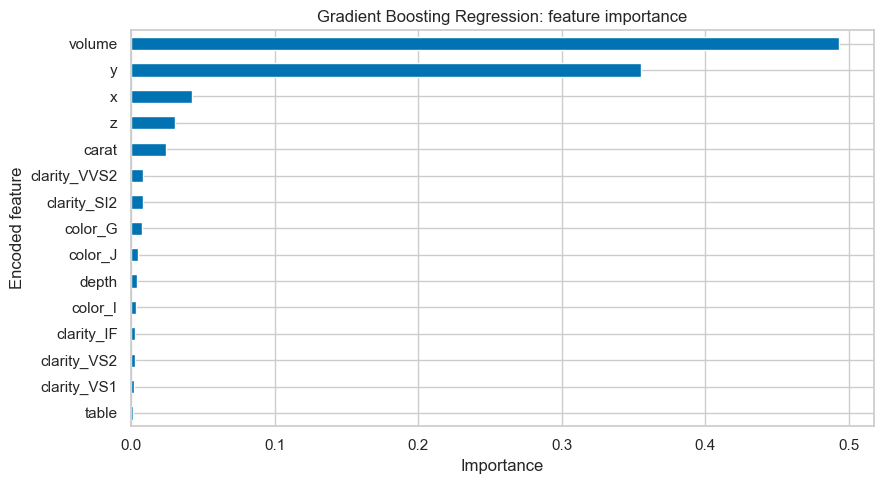

In [13]:
result = review.run_regressor('Gradient Boosting Regression', data)

### Team observation: Gradient Boosting Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Support Vector Regression
Tune C and linear/RBF kernels. Input and target scaling are learned only within training folds.

Support Vector Regression | Best parameters: {'model__regressor__C': 10, 'model__regressor__kernel': 'rbf'} | Training CV R2: 0.9516833232790294


,Metric,Baseline,Tuned,Change
0,R2,0.943576,0.944879,0.001303
1,RMSE,983.745586,972.320440,-11.425146
2,MAE,523.604935,519.597611,-4.007323


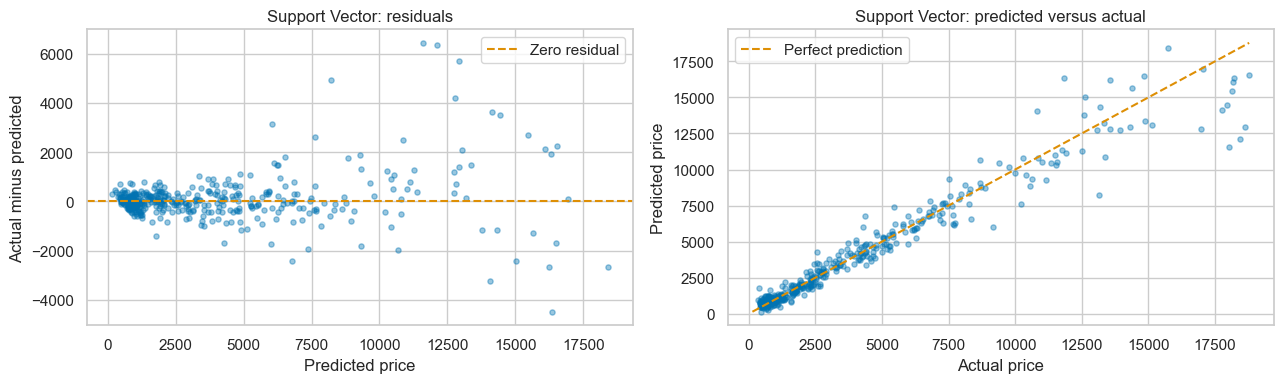

In [14]:
result = review.run_regressor('Support Vector Regression', data)

### Team observation: Support Vector Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## KNN Regression
Tune k and uniform/distance weighting. Scaling prevents large-unit dimensions from dominating distance; the team should discuss its observed effect and limitations.

KNN Regression | Best parameters: {'model__n_neighbors': 11, 'model__weights': 'distance'} | Training CV R2: 0.9164910705660956


,Metric,Baseline,Tuned,Change
0,R2,0.908255,0.908780,0.000525
1,RMSE,1254.412467,1250.820088,-3.592379
2,MAE,701.055714,668.232271,-32.823443


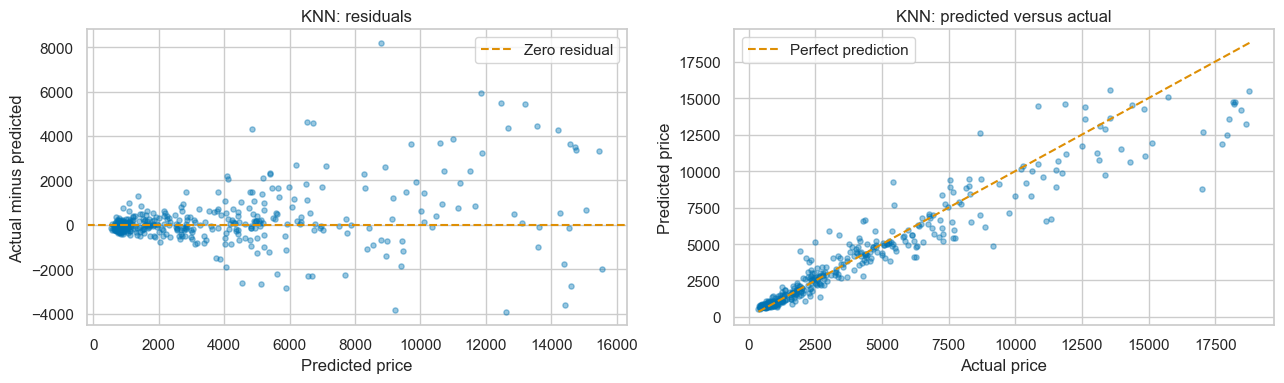

In [15]:
result = review.run_regressor('KNN Regression', data)

### Team observation: KNN Regression: before/after changes and plots

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.

## Ten-model comparison, top-two CV and final model
Rank the comparison by held-out R² as the rubric requests. Report five-fold training CV for the two highest test-R² algorithms. Separately select the website/deployment model by training CV R² to avoid using the test set to choose the final artifact. Show residual and predicted-versus-actual plots for both the CV-selected and highest test-R² models. CV reuses tuning folds and is not a nested-CV estimate.

CV-selected final model: Support Vector Regression | Highest test R2: Support Vector Regression
CV reuses search folds and is not unbiased nested CV. All test metrics are reported in original price units.


,Rank_by_test_R2,Model,R2,RMSE,MAE,CV_R2_Mean,CV_R2_Std
0,1,Support Vector Regression,0.944879,972.320440,519.597611,0.951683,0.006006
1,2,Lasso Regression,0.935244,1053.873517,696.546805,0.934319,0.007598
2,3,Linear Regression,0.935195,1054.271075,697.477719,0.934274,0.007625
3,4,Ridge Regression,0.935157,1054.579628,696.185465,0.934413,0.007420
4,5,ElasticNet Regression,0.935126,1054.834351,695.331291,0.934441,0.007353
5,6,Polynomial Regression,0.934149,1062.744297,692.804134,0.914148,0.048518
6,7,Gradient Boosting Regression,0.930859,1088.975294,511.795296,0.943171,0.006610
7,8,Random Forest Regression,0.924145,1140.622824,549.306027,0.935740,0.007681
8,9,KNN Regression,0.908780,1250.820088,668.232271,0.916491,0.003975
9,10,Decision Tree Regression,0.898813,1317.379766,656.527196,0.895898,0.011599


,Model,Fold,R2,Top_two_test_rank
0,Support Vector Regression,1,0.942450,True
1,Support Vector Regression,2,0.952494,True
2,Support Vector Regression,3,0.950145,True
3,Support Vector Regression,4,0.952055,True
4,Support Vector Regression,5,0.961272,True
5,Lasso Regression,1,0.938988,True
6,Lasso Regression,2,0.939955,True
7,Lasso Regression,3,0.919395,True
8,Lasso Regression,4,0.937543,True
9,Lasso Regression,5,0.935714,True


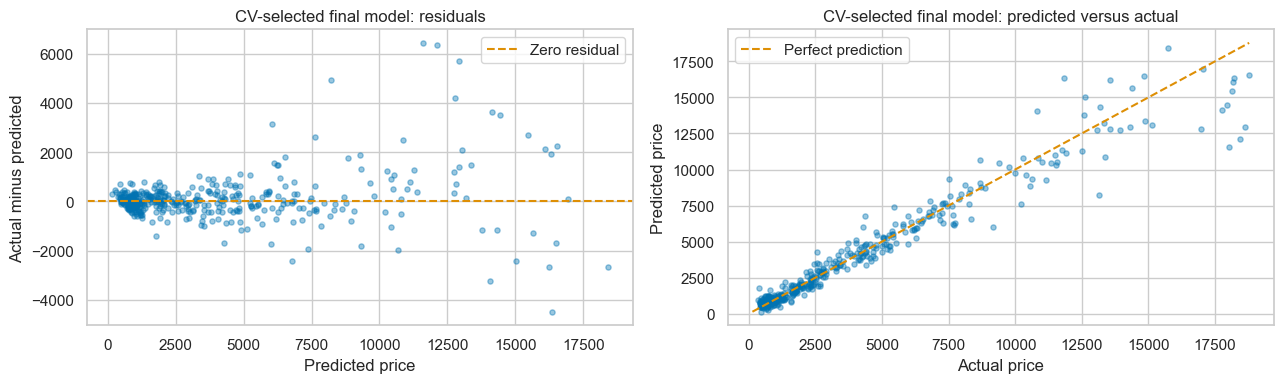

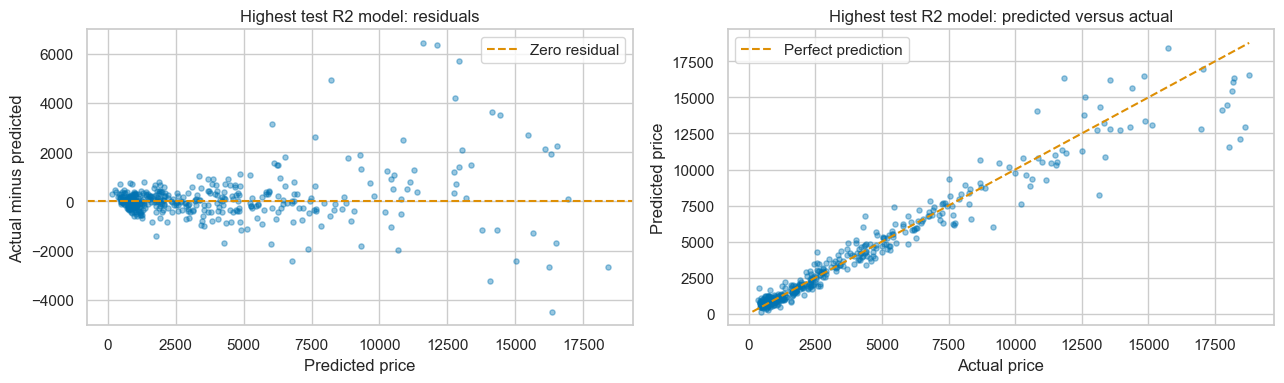

In [16]:
comparison = review.consolidate_regression(data)

### Team observation: final selection, metric trade-offs, feature importance and limitations

**Original team interpretation required.** Explain the evidence above in your own words, naming actual values where useful. Retained original prose is in `r1/audit/original_notebooks.zip`; verify it against this rerun before reusing it. Guideline 7.5 reserves analysis and interpretation for the team.